In [ ]:
!pip install pysyncon

In [ ]:
import pysyncon
print("Library installed successfully!")

Library installed successfully!


In [ ]:
import pandas as pd

df = pd.read_csv('Cleaning Pune Dataset.csv')

print(df.head())

  property_id  location      property_type  area_sqft  bedrooms  bathrooms  \
0       P0001   Kothrud  Independent House        694         2          2   
1       P0002     Aundh  Independent House       1852         3          3   
2       P0003    Pimpri          Apartment       2520         4          4   
3       P0004  Hadapsar          Apartment       2315         4          4   
4       P0005  Hadapsar          Apartment       1039         2          1   

   floor_number  age_years      furnishing parking  distance_km  price_inr  
0            17          6  Semi-Furnished     Yes          2.7    6420000  
1             7         27     Unfurnished     Yes         23.7   15310000  
2             1         22  Semi-Furnished      No         11.7   13990000  
3             4          8  Semi-Furnished     Yes         17.2   17070000  
4            10         17  Semi-Furnished     Yes         21.2    6990000  


In [ ]:
!pip install DoubleML scikit-learn pandas numpy matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 607.8/607.8 kB 13.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.5/15.5 MB 99.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 47.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 531.7/531.7 kB 17.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9/9 [DoubleML]


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import KFold

import doubleml as dml

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
print(df.head())
print(df.shape)
print(df.columns.tolist())

  property_id  location      property_type  area_sqft  bedrooms  bathrooms  \
0       P0001   Kothrud  Independent House        694         2          2   
1       P0002     Aundh  Independent House       1852         3          3   
2       P0003    Pimpri          Apartment       2520         4          4   
3       P0004  Hadapsar          Apartment       2315         4          4   
4       P0005  Hadapsar          Apartment       1039         2          1   

   floor_number  age_years      furnishing parking  distance_km  price_inr  
0            17          6  Semi-Furnished     Yes          2.7    6420000  
1             7         27     Unfurnished     Yes         23.7   15310000  
2             1         22  Semi-Furnished      No         11.7   13990000  
3             4          8  Semi-Furnished     Yes         17.2   17070000  
4            10         17  Semi-Furnished     Yes         21.2    6990000  
(500, 12)
['property_id', 'location', 'property_type', 'area_sqft', '

In [ ]:
# Select Outcome (Y)
Y = df['price_inr']

# Select Treatment (D)
D = df['parking']

# Select Control Variables (X)
X = df[['area_sqft',
        'bedrooms',
        'bathrooms',
        'age_years',
        'location',
        'property_type',
        'furnishing']]

print("Outcome Variable:")
print(Y.head())

print("\nTreatment Variable:")
print(D.head())

print("\nControl Variables:")
print(X.head())

Outcome Variable:
0     6420000
1    15310000
2    13990000
3    17070000
4     6990000
Name: price_inr, dtype: int64

Treatment Variable:
0    Yes
1    Yes
2     No
3    Yes
4    Yes
Name: parking, dtype: object

Control Variables:
   area_sqft  bedrooms  bathrooms  age_years  location      property_type  \
0        694         2          2          6   Kothrud  Independent House   
1       1852         3          3         27     Aundh  Independent House   
2       2520         4          4         22    Pimpri          Apartment   
3       2315         4          4          8  Hadapsar          Apartment   
4       1039         2          1         17  Hadapsar          Apartment   

       furnishing  
0  Semi-Furnished  
1     Unfurnished  
2  Semi-Furnished  
3  Semi-Furnished  
4  Semi-Furnished  


In [ ]:
print(df['parking'].value_counts())

parking
Yes    365
No     135
Name: count, dtype: int64


In [ ]:
df['parking'] = df['parking'].map({
    'Yes': 1,
    'No': 0
})

print(df['parking'].value_counts())

parking
1    365
0    135
Name: count, dtype: int64


In [ ]:
# Outcome variable (Y)
Y = df['price_inr']

# Treatment variable (D)
D = df['parking']

# Control variables (X)
X = df[['area_sqft', 'bedrooms', 'bathrooms',
        'age_years', 'location', 'property_type', 'furnishing']]

print("Outcome variable:")
print(Y.head())

print("\nTreatment variable:")
print(D.head())

print("\nControl variables:")
print(X.head())

Outcome variable:
0     6420000
1    15310000
2    13990000
3    17070000
4     6990000
Name: price_inr, dtype: int64

Treatment variable:
0    1
1    1
2    0
3    1
4    1
Name: parking, dtype: int64

Control variables:
   area_sqft  bedrooms  bathrooms  age_years  location      property_type  \
0        694         2          2          6   Kothrud  Independent House   
1       1852         3          3         27     Aundh  Independent House   
2       2520         4          4         22    Pimpri          Apartment   
3       2315         4          4          8  Hadapsar          Apartment   
4       1039         2          1         17  Hadapsar          Apartment   

       furnishing  
0  Semi-Furnished  
1     Unfurnished  
2  Semi-Furnished  
3  Semi-Furnished  
4  Semi-Furnished  


In [ ]:
X = pd.get_dummies(
    X,
    columns=['location', 'property_type', 'furnishing'],
    drop_first=True,
    dtype=int
)

print(X.head())
print(X.shape)

   area_sqft  bedrooms  bathrooms  age_years  location_Baner  \
0        694         2          2          6               0   
1       1852         3          3         27               0   
2       2520         4          4         22               0   
3       2315         4          4          8               0   
4       1039         2          1         17               0   

   location_Dhankawadi  location_Hadapsar  location_Hinjewadi  \
0                    0                  0                   0   
1                    0                  0                   0   
2                    0                  0                   0   
3                    0                  1                   0   
4                    0                  1                   0   

   location_Kharadi  location_Kothrud  location_Pimpri  location_Wagholi  \
0                 0                 1                0                 0   
1                 0                 0                0                 0

In [ ]:
# Combine Y, D and X into one dataset
dml_data = pd.concat([Y, D, X], axis=1)

# Check the dataset
print(dml_data.head())

# Check data types
print(dml_data.dtypes)

# Check missing values
print(dml_data.isnull().sum().sum())

   price_inr  parking  area_sqft  bedrooms  bathrooms  age_years  \
0    6420000        1        694         2          2          6   
1   15310000        1       1852         3          3         27   
2   13990000        0       2520         4          4         22   
3   17070000        1       2315         4          4          8   
4    6990000        1       1039         2          1         17   

   location_Baner  location_Dhankawadi  location_Hadapsar  location_Hinjewadi  \
0               0                    0                  0                   0   
1               0                    0                  0                   0   
2               0                    0                  0                   0   
3               0                    0                  1                   0   
4               0                    0                  1                   0   

   location_Kharadi  location_Kothrud  location_Pimpri  location_Wagholi  \
0                 0         

In [ ]:
dml_dataset = dml.DoubleMLData(
    dml_data,
    y_col='price_inr',
    d_cols='parking'
)

print(dml_dataset)

================== DoubleMLData Object ==================

------------------ Data summary      ------------------
Outcome variable: price_inr
Treatment variable(s): ['parking']
Covariates: ['area_sqft', 'bedrooms', 'bathrooms', 'age_years', 'location_Baner', 'location_Dhankawadi', 'location_Hadapsar', 'location_Hinjewadi', 'location_Kharadi', 'location_Kothrud', 'location_Pimpri', 'location_Wagholi', 'location_Wakad', 'property_type_Independent House', 'property_type_Villa', 'furnishing_Semi-Furnished', 'furnishing_Unfurnished']
Instrument variable(s): None
No. Observations: 500
------------------ DataFrame info    ------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Columns: 19 entries, price_inr to furnishing_Unfurnished
dtypes: int64(19)
memory usage: 74.3 KB



In [ ]:
# Create machine learning models
ml_g = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

ml_m = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

# Create DML model
dml_model = dml.DoubleMLIRM(
    dml_dataset,
    ml_g=ml_g,
    ml_m=ml_m,
    n_folds=5
)

print("DML model created successfully!")

DML model created successfully!


In [ ]:
# Train the DML model
dml_model.fit()

print("DML estimation completed successfully!")

DML estimation completed successfully!


In [ ]:
# Display DML results
print(dml_model.summary)

                  coef        std err         t     P>|t|          2.5 %  \
parking  268430.083164  284388.459541  0.943885  0.345228 -288961.055156   

                97.5 %  
parking  825821.221484  


In [ ]:
dml_model.fit()
print(dml_model.summary)

                  coef        std err         t     P>|t|          2.5 %  \
parking  268430.083164  284388.459541  0.943885  0.345228 -288961.055156   

                97.5 %  
parking  825821.221484  


In [ ]:
print("Estimated Treatment Effect:", dml_model.coef)
print("Standard Error:", dml_model.se)
print("P-value:", dml_model.pval)
print("Confidence Interval:")
print(dml_model.confint())

Estimated Treatment Effect: [268430.08316382]
Standard Error: [284388.45954133]
P-value: [0.34522827]
Confidence Interval:
                 2.5 %         97.5 %
parking -288961.055156  825821.221484


In [ ]:
print(df['parking'].value_counts())

parking
1    365
0    135
Name: count, dtype: int64


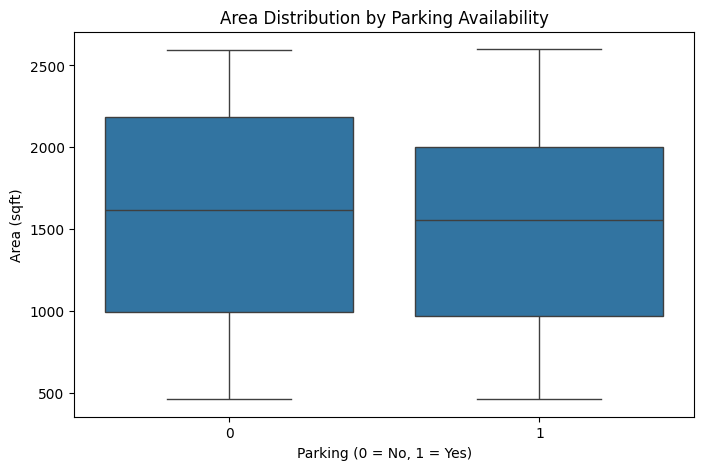

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(
    x='parking',
    y='area_sqft',
    data=df
)

plt.title('Area Distribution by Parking Availability')
plt.xlabel('Parking (0 = No, 1 = Yes)')
plt.ylabel('Area (sqft)')

plt.show()

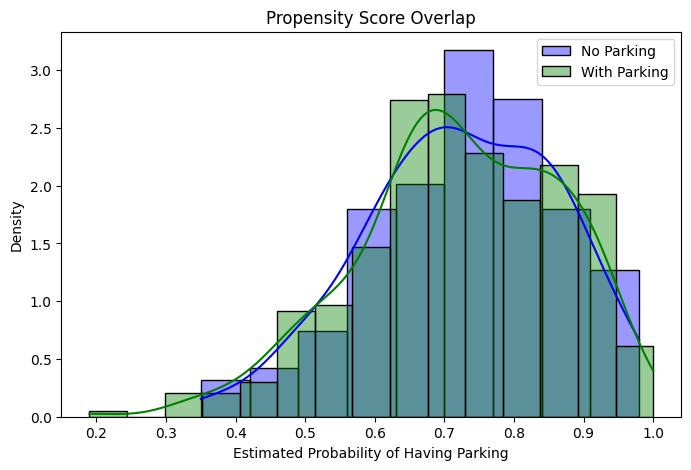

In [ ]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier

# Estimate parking probabilities
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

propensity_scores = cross_val_predict(
    RandomForestClassifier(n_estimators=100, random_state=42),
    X,
    D,
    cv=cv,
    method='predict_proba'
)[:, 1]

# Plot propensity score distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    propensity_scores[D == 0],
    color='blue',
    label='No Parking',
    kde=True,
    stat='density',
    alpha=0.4
)

sns.histplot(
    propensity_scores[D == 1],
    color='green',
    label='With Parking',
    kde=True,
    stat='density',
    alpha=0.4
)

plt.title('Propensity Score Overlap')
plt.xlabel('Estimated Probability of Having Parking')
plt.ylabel('Density')
plt.legend()
plt.show()

In [ ]:
# Separate propensity scores by parking group
no_parking = propensity_scores[np.array(D) == 0]
with_parking = propensity_scores[np.array(D) == 1]

# Find common support
lower_limit = max(no_parking.min(), with_parking.min())
upper_limit = min(no_parking.max(), with_parking.max())

print("No Parking Range:", no_parking.min(), "to", no_parking.max())
print("With Parking Range:", with_parking.min(), "to", with_parking.max())

print("Common Support Range:", lower_limit, "to", upper_limit)

No Parking Range: 0.35 to 0.98
With Parking Range: 0.19 to 1.0
Common Support Range: 0.35 to 0.98


In [ ]:
outside_support = (
    (propensity_scores < lower_limit) |
    (propensity_scores > upper_limit)
)

print("Total properties:", len(propensity_scores))
print("Properties outside common support:", outside_support.sum())
print("Properties inside common support:", (~outside_support).sum())

Total properties: 500
Properties outside common support: 6
Properties inside common support: 494


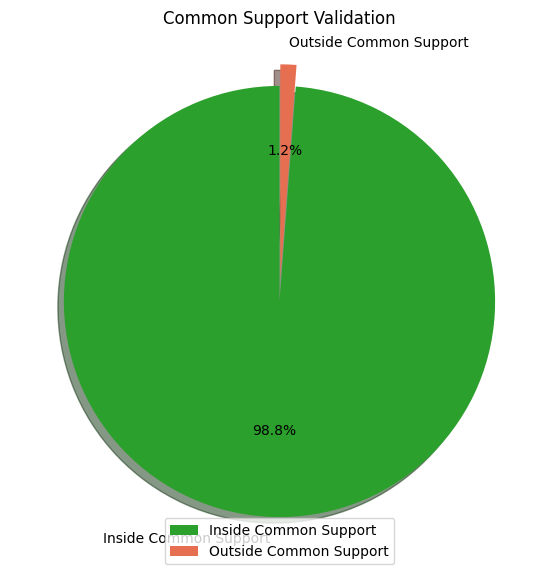

In [ ]:
import matplotlib.pyplot as plt

labels = ['Inside Common Support', 'Outside Common Support']
values = [494, 6]
colors = ['#2CA02C', '#E76F51']

plt.figure(figsize=(7, 7))

plt.pie(
    values,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    explode=(0, 0.1),
    shadow=True
)

plt.title('Common Support Validation')
plt.legend(labels, loc='lower center')
plt.show()

In [ ]:
print("Original DML Coefficient:", dml_model.coef)
print("Original Standard Error:", dml_model.se)

Original DML Coefficient: [268430.08316382]
Original Standard Error: [284388.45954133]


In [ ]:
from sklearn.ensemble import ExtraTreesRegressor, ExtraTreesClassifier

# Alternative outcome model
ml_g_alt = ExtraTreesRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

# Alternative treatment model
ml_m_alt = ExtraTreesClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

# Create alternative DML model
dml_model_alt = dml.DoubleMLIRM(
    dml_dataset,
    ml_g=ml_g_alt,
    ml_m=ml_m_alt,
    n_folds=5
)

# Fit the alternative model
dml_model_alt.fit()

print("Alternative DML estimation completed!")

Alternative DML estimation completed!


In [ ]:
print("Original Random Forest DML:")
print("Coefficient:", dml_model.coef)
print("Standard Error:", dml_model.se)

print("\nAlternative Extra Trees DML:")
print("Coefficient:", dml_model_alt.coef)
print("Standard Error:", dml_model_alt.se)

Original Random Forest DML:
Coefficient: [268430.08316382]
Standard Error: [284388.45954133]

Alternative Extra Trees DML:
Coefficient: [227079.86302432]
Standard Error: [292943.75419096]


In [ ]:
print("ORIGINAL DML (Random Forest)")
print("Coefficient:", dml_model.coef)
print("Standard Error:", dml_model.se)

print("\nALTERNATIVE DML (Extra Trees)")
print("Coefficient:", dml_model_alt.coef)
print("Standard Error:", dml_model_alt.se)

ORIGINAL DML (Random Forest)
Coefficient: [268430.08316382]
Standard Error: [284388.45954133]

ALTERNATIVE DML (Extra Trees)
Coefficient: [227079.86302432]
Standard Error: [292943.75419096]


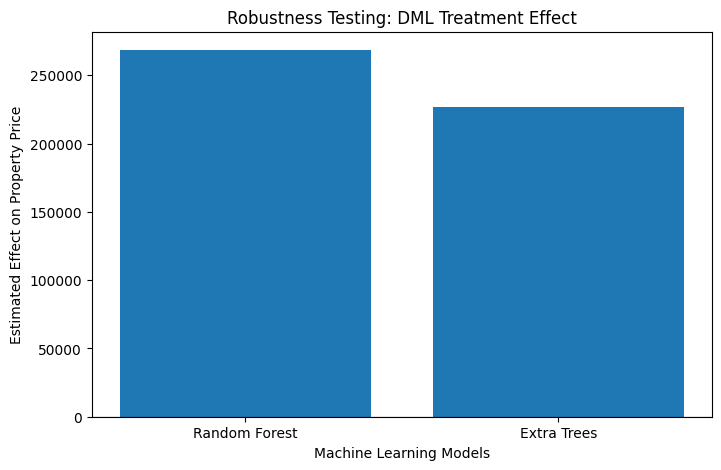

In [ ]:
import matplotlib.pyplot as plt

models = ['Random Forest', 'Extra Trees']
effects = [
    float(dml_model.coef[0]),
    float(dml_model_alt.coef[0])
]

plt.figure(figsize=(8, 5))
plt.bar(models, effects)

plt.axhline(0, color='black', linewidth=0.8)
plt.title('Robustness Testing: DML Treatment Effect')
plt.xlabel('Machine Learning Models')
plt.ylabel('Estimated Effect on Property Price')

plt.show()

In [ ]:
comparison = pd.DataFrame({
    'Model': ['Random Forest', 'Extra Trees'],
    'Coefficient': [
        dml_model.coef[0],
        dml_model_alt.coef[0]
    ],
    'Standard Error': [
        dml_model.se[0],
        dml_model_alt.se[0]
    ],
    'P-value': [
        dml_model.pval[0],
        dml_model_alt.pval[0]
    ]
})

print(comparison)

           Model    Coefficient  Standard Error   P-value
0  Random Forest  268430.083164   284388.459541  0.345228
1    Extra Trees  227079.863024   292943.754191  0.438242


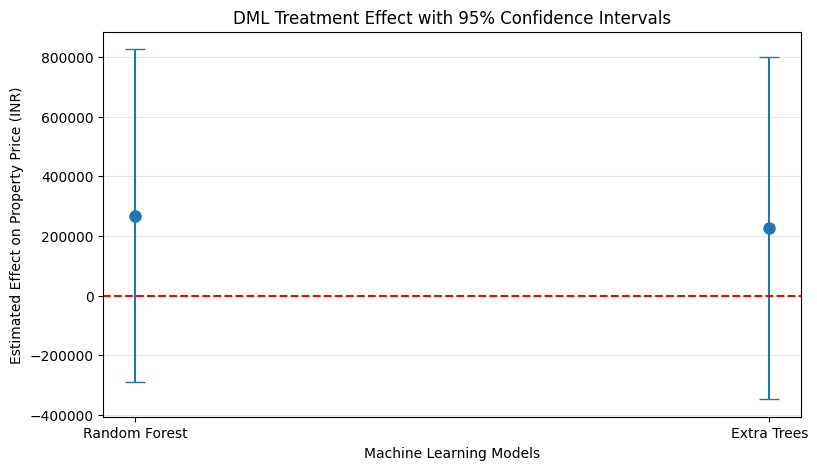

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

models = ['Random Forest', 'Extra Trees']

coefficients = [
    dml_model.coef[0],
    dml_model_alt.coef[0]
]

errors = [
    1.96 * dml_model.se[0],
    1.96 * dml_model_alt.se[0]
]

plt.figure(figsize=(9, 5))

plt.errorbar(
    models,
    coefficients,
    yerr=errors,
    fmt='o',
    capsize=7,
    markersize=8
)

plt.axhline(0, linestyle='--', color='red')
plt.title('DML Treatment Effect with 95% Confidence Intervals')
plt.xlabel('Machine Learning Models')
plt.ylabel('Estimated Effect on Property Price (INR)')
plt.grid(axis='y', alpha=0.3)
plt.show()

In [ ]:
from sklearn.metrics import roc_auc_score, accuracy_score, brier_score_loss
from sklearn.ensemble import RandomForestClassifier

# Predict parking availability using 5-fold cross-validation
parking_predictions = cross_val_predict(
    RandomForestClassifier(n_estimators=100, random_state=42),
    X,
    D,
    cv=cv,
    method='predict'
)

print("Treatment Model Accuracy:",
      accuracy_score(D, parking_predictions))

print("Treatment Model ROC-AUC:",
      roc_auc_score(D, propensity_scores))

print("Treatment Model Brier Score:",
      brier_score_loss(D, propensity_scores))

Treatment Model Accuracy: 0.688
Treatment Model ROC-AUC: 0.4943480466768138
Treatment Model Brier Score: 0.21950099999999997


In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestRegressor

# Properties without parking
X0 = X.loc[D == 0]
Y0 = Y.loc[D == 0]

# Properties with parking
X1 = X.loc[D == 1]
Y1 = Y.loc[D == 1]

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

score0 = cross_val_score(model, X0, Y0, cv=5, scoring='r2')
score1 = cross_val_score(model, X1, Y1, cv=5, scoring='r2')

print("R2 Score - No Parking:", score0.mean())
print("R2 Score - With Parking:", score1.mean())

R2 Score - No Parking: 0.7605070677793051
R2 Score - With Parking: 0.8610071914052945


In [ ]:
# Create new Random Forest models
ml_g_sens = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

ml_m_sens = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

# Create DML model with 3 folds
dml_sensitivity = dml.DoubleMLIRM(
    dml_dataset,
    ml_g=ml_g_sens,
    ml_m=ml_m_sens,
    n_folds=3
)

# Fit the model
dml_sensitivity.fit()

print("Sensitivity analysis completed!")

Sensitivity analysis completed!


In [ ]:
print("Original DML - 5 Folds")
print("Coefficient:", dml_model.coef)
print("Standard Error:", dml_model.se)

print("\nSensitivity DML - 3 Folds")
print("Coefficient:", dml_sensitivity.coef)
print("Standard Error:", dml_sensitivity.se)

Original DML - 5 Folds
Coefficient: [268430.08316382]
Standard Error: [284388.45954133]

Sensitivity DML - 3 Folds
Coefficient: [351821.96363227]
Standard Error: [279124.51678053]


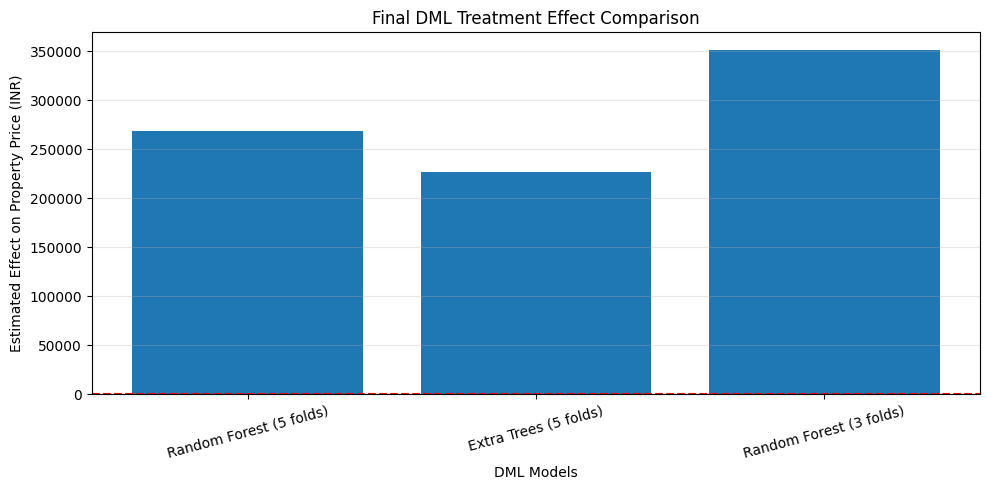

In [ ]:
import matplotlib.pyplot as plt

models = ['Random Forest (5 folds)',
          'Extra Trees (5 folds)',
          'Random Forest (3 folds)']

effects = [
    dml_model.coef[0],
    dml_model_alt.coef[0],
    dml_sensitivity.coef[0]
]

plt.figure(figsize=(10, 5))

plt.bar(models, effects)

plt.axhline(0, color='red', linestyle='--')

plt.title('Final DML Treatment Effect Comparison')
plt.xlabel('DML Models')
plt.ylabel('Estimated Effect on Property Price (INR)')

plt.xticks(rotation=15)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [50]:
# Check dataset and existing DML model

print("Dataset columns:")
print(df.columns.tolist())

print("\nDataset shape:")
print(df.shape)

print("\nProperty types:")
print(df["property_type"].value_counts())

print("\nLocations:")
print(df["location"].value_counts())

Dataset columns:
['property_id', 'location', 'property_type', 'area_sqft', 'bedrooms', 'bathrooms', 'floor_number', 'age_years', 'furnishing', 'parking', 'distance_km', 'price_inr']

Dataset shape:
(500, 12)

Property types:
property_type
Apartment            370
Independent House     88
Villa                 42
Name: count, dtype: int64

Locations:
location
Hadapsar      64
Aundh         59
Baner         58
Dhankawadi    49
Kothrud       47
Pimpri        47
Wagholi       46
Hinjewadi     44
Kharadi       43
Wakad         43
Name: count, dtype: int64


In [51]:
!pip install --upgrade DoubleML

In [54]:
%whos

Variable                 Type                      Data/Info
------------------------------------------------------------
D                        Series                    0      1\n1      1\n2    <...>Length: 500, dtype: int64
ExtraTreesClassifier     ABCMeta                   <class 'sklearn.ensemble.<...>st.ExtraTreesClassifier'>
ExtraTreesRegressor      ABCMeta                   <class 'sklearn.ensemble.<...>est.ExtraTreesRegressor'>
KFold                    ABCMeta                   <class 'sklearn.model_selection._split.KFold'>
RandomForestClassifier   ABCMeta                   <class 'sklearn.ensemble.<...>.RandomForestClassifier'>
RandomForestRegressor    ABCMeta                   <class 'sklearn.ensemble.<...>t.RandomForestRegressor'>
StratifiedKFold          ABCMeta                   <class 'sklearn.model_sel<...>._split.StratifiedKFold'>
X                        DataFrame                      area_sqft  bedrooms <...>\n[500 rows x 17 columns]
X0                       DataFr

In [55]:
for name, obj in globals().copy().items():
    if "DoubleML" in str(type(obj)):
        print(name, type(obj))

dml_dataset <class 'doubleml.data.base_data.DoubleMLData'>
dml_model <class 'doubleml.irm.irm.DoubleMLIRM'>
dml_model_alt <class 'doubleml.irm.irm.DoubleMLIRM'>
dml_sensitivity <class 'doubleml.irm.irm.DoubleMLIRM'>


In [56]:
for name, obj in globals().copy().items():
    if "DoubleML" in str(type(obj)):
        print("Variable name:", name)
        print("Class:", type(obj))
        print("-------------------")

Variable name: dml_dataset
Class: <class 'doubleml.data.base_data.DoubleMLData'>
-------------------
Variable name: dml_model
Class: <class 'doubleml.irm.irm.DoubleMLIRM'>
-------------------
Variable name: dml_model_alt
Class: <class 'doubleml.irm.irm.DoubleMLIRM'>
-------------------
Variable name: dml_sensitivity
Class: <class 'doubleml.irm.irm.DoubleMLIRM'>
-------------------


In [57]:
print(type(dml_model))
print(dml_model)

<class 'doubleml.irm.irm.DoubleMLIRM'>
================== DoubleMLIRM Object ==================

------------------ Data Summary      ------------------
Outcome variable: price_inr
Treatment variable(s): ['parking']
Covariates: ['area_sqft', 'bedrooms', 'bathrooms', 'age_years', 'location_Baner', 'location_Dhankawadi', 'location_Hadapsar', 'location_Hinjewadi', 'location_Kharadi', 'location_Kothrud', 'location_Pimpri', 'location_Wagholi', 'location_Wakad', 'property_type_Independent House', 'property_type_Villa', 'furnishing_Semi-Furnished', 'furnishing_Unfurnished']
Instrument variable(s): None
No. Observations: 500

------------------ Score & Algorithm ------------------
Score function: ATE

------------------ Machine Learner   ------------------
Learner ml_g: RandomForestRegressor(max_depth=5, random_state=42)
Learner ml_m: RandomForestClassifier(max_depth=5, random_state=42)
Out-of-sample Performance:
Regression:
Learner ml_g0 RMSE: [[2892249.68282822]]
Learner ml_g1 RMSE: [[220636

In [59]:
print("ATE:", dml_model.coef)
print("Standard Error:", dml_model.se)
print("Sensitivity analysis method:")
print(hasattr(dml_model, "sensitivity_analysis"))

ATE: [268430.08316382]
Standard Error: [284388.45954133]
Sensitivity analysis method:
True


In [60]:
dml_model.sensitivity_analysis(
    cf_y=0.03,
    cf_d=0.03,
    rho=1.0
)

print(dml_model.sensitivity_summary)

================== Sensitivity Analysis ==================

------------------ Scenario          ------------------
Significance Level: level=0.95
Sensitivity parameters: cf_y=0.03; cf_d=0.03, rho=1.0

------------------ Bounds with CI    ------------------
              CI lower   theta lower          theta    theta upper  \
parking -358528.775011  109796.00693  268430.083164  427064.159398   

              CI upper  
parking  894755.517933  

------------------ Robustness Values ------------------
         H_0    RV (%)  RVa (%)
parking  0.0  5.023211  0.00058


In [61]:
print(type(dml_model))
print(dml_model.coef)
print(dml_model.se)

<class 'doubleml.irm.irm.DoubleMLIRM'>
[268430.08316382]
[284388.45954133]


In [62]:
print(df.columns.tolist())
print(df.shape)
print(df[['property_type', 'location', 'parking', 'price_inr']].head())

['property_id', 'location', 'property_type', 'area_sqft', 'bedrooms', 'bathrooms', 'floor_number', 'age_years', 'furnishing', 'parking', 'distance_km', 'price_inr']
(500, 12)
       property_type  location  parking  price_inr
0  Independent House   Kothrud        1    6420000
1  Independent House     Aundh        1   15310000
2          Apartment    Pimpri        0   13990000
3          Apartment  Hadapsar        1   17070000
4          Apartment  Hadapsar        1    6990000


In [63]:
# Check whether the fitted DML model supports CATE estimation
print("CATE method available:",
      hasattr(dml_model, "cate"))

print("GATE method available:",
      hasattr(dml_model, "gate"))

print("Available prediction method:",
      hasattr(dml_model, "predict"))

CATE method available: True
GATE method available: True
Available prediction method: False


In [66]:
from sklearn.preprocessing import PolynomialFeatures
import pandas as pd

X_cate = df[
    ['area_sqft', 'bedrooms', 'bathrooms', 'age_years']
]

poly = PolynomialFeatures(
    degree=2,
    include_bias=False
)

basis_array = poly.fit_transform(X_cate)

basis_df = pd.DataFrame(
    basis_array,
    columns=poly.get_feature_names_out(X_cate.columns),
    index=X_cate.index
)

print(basis_df.head())

   area_sqft  bedrooms  bathrooms  age_years  area_sqft^2  area_sqft bedrooms  \
0      694.0       2.0        2.0        6.0     481636.0              1388.0   
1     1852.0       3.0        3.0       27.0    3429904.0              5556.0   
2     2520.0       4.0        4.0       22.0    6350400.0             10080.0   
3     2315.0       4.0        4.0        8.0    5359225.0              9260.0   
4     1039.0       2.0        1.0       17.0    1079521.0              2078.0   

   area_sqft bathrooms  area_sqft age_years  bedrooms^2  bedrooms bathrooms  \
0               1388.0               4164.0         4.0                 4.0   
1               5556.0              50004.0         9.0                 9.0   
2              10080.0              55440.0        16.0                16.0   
3               9260.0              18520.0        16.0                16.0   
4               1039.0              17663.0         4.0                 2.0   

   bedrooms age_years  bathrooms^2  ba

In [67]:
cate_results = dml_model.cate(
    basis=basis_df,
    X=X_cate
)

print(cate_results)

================== DoubleMLBLP Object ==================

------------------ Fit summary ------------------
                             coef       std err         t     P>|t|  \
area_sqft           -8.440372e+02  2.654702e+03 -0.317940  0.750530   
bedrooms             7.285754e+05  2.992556e+06  0.243463  0.807647   
bathrooms           -1.225594e+06  2.629251e+06 -0.466138  0.641117   
age_years            8.432586e+04  1.315875e+05  0.640835  0.521630   
area_sqft^2          1.361637e+00  1.268262e+00  1.073624  0.282991   
area_sqft bedrooms  -1.717878e+03  2.052011e+03 -0.837168  0.402498   
area_sqft bathrooms  4.519246e+02  1.644666e+03  0.274782  0.783484   
area_sqft age_years  4.722218e+01  1.018461e+02  0.463662  0.642890   
bedrooms^2           1.158089e+06  1.412717e+06  0.819760  0.412353   
bedrooms bathrooms  -7.733154e+05  1.884384e+06 -0.410381  0.681527   
bedrooms age_years  -1.239318e+05  1.193944e+05 -1.038004  0.299268   
bathrooms^2          1.641744e+05  7.209

              2.5 %        effect        97.5 %       x_area
count  5.000000e+02  5.000000e+02  5.000000e+02   500.000000
mean  -1.697247e+06  2.522316e+05  2.201710e+06  1539.722000
std    1.126832e+06  7.848562e+05  1.439498e+06   627.039023
min   -7.856295e+06 -2.145563e+06  3.080855e+05   459.000000
25%   -1.977511e+06 -2.544762e+05  1.136832e+06   977.500000
50%   -1.376681e+06  1.466337e+05  1.778439e+06  1575.500000
75%   -1.032564e+06  6.359976e+05  2.953032e+06  2100.000000
max   -2.722923e+05  5.076869e+06  1.063626e+07  2599.000000


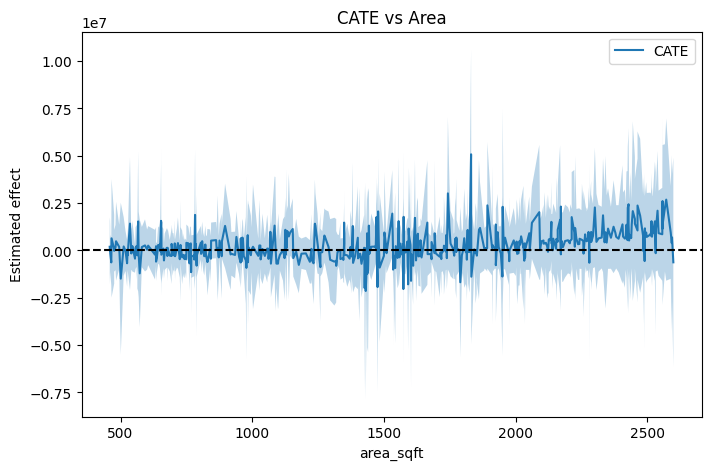

In [68]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ci = cate_results.confint(basis=basis_df, level=0.95)
ci["x_area"] = X_cate["area_sqft"].values
ci = ci.sort_values("x_area")
print(ci.describe())

plt.figure(figsize=(8,5))
plt.plot(ci["x_area"], ci["effect"], label="CATE")
plt.fill_between(ci["x_area"], ci["2.5 %"], ci["97.5 %"], alpha=0.3)
plt.axhline(0, color="k", ls="--")
plt.xlabel("area_sqft"); plt.ylabel("Estimated effect")
plt.title("CATE vs Area"); plt.legend(); plt.show()

In [69]:
basis_lin = pd.DataFrame(X_cate[["area_sqft","bedrooms","bathrooms","age_years"]])
basis_lin.insert(0, "const", 1)   # skip if your basis already has an intercept
cate_lin = dml_model.cate(basis=basis_lin, X=X_cate)
print(cate_lin.summary)

                    coef        std err         t     P>|t|        [0.025  \
const     -628163.126997  760687.425199 -0.825784  0.408927 -2.119083e+06   
area_sqft     974.457248     786.070379  1.239656  0.215102 -5.662124e+02   
bedrooms  -119695.555571  855444.745419 -0.139922  0.888722 -1.796336e+06   
bathrooms -281064.942404  676819.985954 -0.415273  0.677942 -1.607608e+06   
age_years   24488.270881   35171.522673  0.696253  0.486271 -4.444665e+04   

                 0.975]  
const      8.627568e+05  
area_sqft  2.515127e+03  
bedrooms   1.556945e+06  
bathrooms  1.045478e+06  
age_years  9.342319e+04  


In [71]:
print(dml_model.summary)

                  coef        std err         t     P>|t|          2.5 %  \
parking  268430.083164  284388.459541  0.943885  0.345228 -288961.055156   

                97.5 %  
parking  825821.221484  
